# ADMET EDA

Five molecular datasets from TDC (Therapeutics Data Commons). Each maps a **SMILES string** — a text encoding of a molecular structure, e.g. `CCO` = ethanol — to a measured biological property.

| Endpoint      | Property                                                         | Task           | Source       |
| ------------- | ---------------------------------------------------------------- | -------------- | ------------ |
| Solubility    | logS — how well a molecule dissolves in water (mol/L, log scale) | Regression     | AqSolDB      |
| Lipophilicity | logD — fat vs. water preference at blood pH 7.4                  | Regression     | AstraZeneca  |
| CYP3A4        | Does it inhibit the CYP3A4 liver enzyme?                         | Classification | Veith et al. |
| Clearance     | How fast the liver removes it (mL/min/kg)                        | Regression     | AstraZeneca  |
| hERG          | Does it block the hERG cardiac ion channel?                      | Classification | Karim et al. |


In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from src.constants import Endpoint
from src.paths import RAW

dfs = {ep: pd.read_parquet(RAW / f"{ep}.parquet") for ep in Endpoint}

for ep, df in dfs.items():
    print(f"{ep:40s}  {len(df):>6,} rows")

Solubility_AqSolDB                         9,982 rows
Lipophilicity_AstraZeneca                  4,200 rows
CYP3A4_Veith                              12,328 rows
Clearance_Hepatocyte_AZ                    1,213 rows
hERG                                         655 rows


---

## 1. Solubility (logS)

**What it is:** Aqueous solubility — how much of the drug dissolves in water. Measured as log₁₀(mol/L).

**Why it matters:** A drug that won't dissolve can't be absorbed from the gut. Below logS ≈ −4 (0.1 mM) is a red flag for oral bioavailability.

**Dataset:** AqSolDB — ~10k experimentally measured values curated from literature.


In [2]:
df = dfs[Endpoint.SOLUBILITY]
df.head()

,Drug_ID,Drug,Y
0,"N,N,N-trimethyloctadecan-1-aminium bromide",CCCCCCCCCCCCCCCCCC[N+](C)(C)C.[Br-],-3.616127
1,Benzo[cd]indol-2(1H)-one,O=C1Nc2cccc3cccc1c23,-3.254767
2,4-chlorobenzaldehyde,O=Cc1ccc(Cl)cc1,-2.177078
3,"zinc bis[2-hydroxy-3,5-bis(1-phenylethyl)benzo...",CC(c1ccccc1)c1cc(C(=O)[O-])c(O)c(C(C)c2ccccc2)...,-3.924409
4,4-({4-[bis(oxiran-2-ylmethyl)amino]phenyl}meth...,c1cc(N(CC2CO2)CC2CO2)ccc1Cc1ccc(N(CC2CO2)CC2CO...,-4.662065


In [3]:
df["Y"].describe().round(2)

count    9982.00
mean       -2.89
std         2.37
min       -13.17
25%        -4.33
50%        -2.62
75%        -1.21
max         2.14
Name: Y, dtype: float64

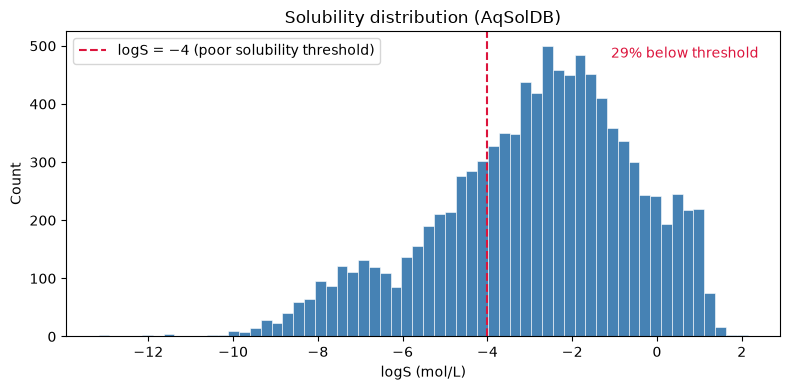

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["Y"], bins=60, color="steelblue", edgecolor="white", linewidth=0.4)
ax.axvline(-4, color="crimson", linestyle="--", label="logS = −4 (poor solubility threshold)")
ax.set_xlabel("logS (mol/L)")
ax.set_ylabel("Count")
ax.set_title("Solubility distribution (AqSolDB)")
ax.legend()
pct_poor = (df["Y"] < -4).mean() * 100
ax.text(0.97, 0.95, f"{pct_poor:.0f}% below threshold", transform=ax.transAxes,
        ha="right", va="top", color="crimson")
plt.tight_layout()
plt.show()

---

## 2. Lipophilicity (logD)

**What it is:** How much a molecule prefers fat (octanol) over water, at blood pH 7.4. Higher = more lipophilic.

**Why it matters:** Lipophilic molecules cross cell membranes more easily but tend to accumulate in fatty tissue and be metabolized quickly. Lipinski's Rule of 5 caps logD < 5 for oral drugs. Too low and the drug won't cross membranes; too high and it won't stay in circulation.

**Dataset:** AstraZeneca internal measurements — 4200 drug-like compounds.


In [5]:
df = dfs[Endpoint.LIPOPHILICITY]
df.head()

,Drug_ID,Drug,Y
0,CHEMBL596271,Cn1c(CN2CCN(c3ccc(Cl)cc3)CC2)nc2ccccc21,3.54
1,CHEMBL1951080,COc1cc(OC)c(S(=O)(=O)N2c3ccccc3CCC2C)cc1NC(=O)...,-1.18
2,CHEMBL1771,COC(=O)[C@H](c1ccccc1Cl)N1CCc2sccc2C1,3.69
3,CHEMBL234951,O=C(NC1Cc2ccccc2N(C[C@@H](O)CO)C1=O)c1cc2cc(Cl...,3.37
4,CHEMBL565079,Cc1cccc(C[C@H](NC(=O)c2cc(C(C)(C)C)nn2C)C(=O)N...,3.10


In [6]:
df["Y"].describe().round(2)

count    4200.00
mean        2.19
std         1.20
min        -1.50
25%         1.41
50%         2.36
75%         3.10
max         4.50
Name: Y, dtype: float64

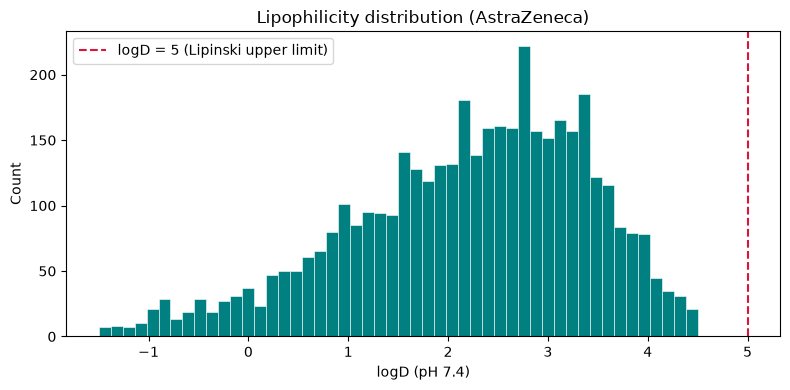

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["Y"], bins=50, color="teal", edgecolor="white", linewidth=0.4)
ax.axvline(5, color="crimson", linestyle="--", label="logD = 5 (Lipinski upper limit)")
ax.set_xlabel("logD (pH 7.4)")
ax.set_ylabel("Count")
ax.set_title("Lipophilicity distribution (AstraZeneca)")
ax.legend()
plt.tight_layout()
plt.show()

---

## 3. CYP3A4 Inhibition

**What it is:** Binary label — does the molecule inhibit the CYP3A4 enzyme? `1` = inhibitor, `0` = non-inhibitor.

**Why it matters:** CYP3A4 is the most important drug-metabolizing enzyme in the liver — responsible for ~50% of all drug metabolism. If your drug inhibits CYP3A4, it slows the metabolism of other co-administered drugs, pushing their plasma concentrations to potentially toxic levels. This is a major source of drug-drug interactions and a key safety filter in early drug discovery.

**Dataset:** Veith et al. — ~12k compounds screened in a PubChem assay.


In [8]:
df = dfs[Endpoint.CYP3A4]
df.head()

,Drug_ID,Drug,Y
0,6602638.0,CCCC(=O)Nc1ccc(N2CCN(CC)CC2)c(Cl)c1.Cl,0
1,644510.0,O=c1[nH]c2cc3c(cc2cc1CN(CCCO)Cc1nnnn1Cc1ccc(F)...,1
2,644675.0,CC(=O)N(c1ccc2oc(=O)sc2c1)S(=O)(=O)c1cccs1,1
3,644890.0,COc1ccccc1C(c1nnnn1C(C)(C)C)N1CCN(Cc2ccncc2)CC1,1
4,645063.0,CC(=O)Nc1cccc(NC(=O)C2CCCN2C(=O)Nc2ccccc2C)c1,0


In [9]:
counts = df["Y"].value_counts().sort_index()
print(counts)
print(f"\nClass balance: {counts[1]/len(df)*100:.1f}% inhibitors")

Y
0    7218
1    5110
Name: count, dtype: int64

Class balance: 41.5% inhibitors


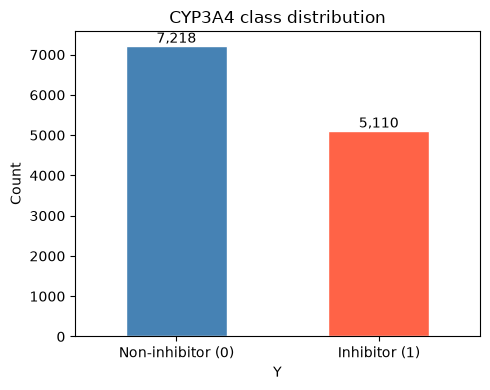

In [10]:
fig, ax = plt.subplots(figsize=(5, 4))
counts.plot(kind="bar", ax=ax, color=["steelblue", "tomato"], edgecolor="white", rot=0)
ax.set_xticklabels(["Non-inhibitor (0)", "Inhibitor (1)"])
ax.set_ylabel("Count")
ax.set_title("CYP3A4 class distribution")
for i, v in enumerate(counts):
    ax.text(i, v + 80, f"{v:,}", ha="center", fontsize=10)
plt.tight_layout()
plt.show()

---

## 4. Hepatic Clearance

**What it is:** How fast the liver removes a drug from the bloodstream, in mL/min/kg body weight.

**Why it matters:** High clearance = short half-life = drug disappears quickly, requiring frequent dosing or high doses. Low clearance = drug accumulates, which is usually desirable but risks toxicity buildup. Target range for most oral drugs is 1–10 mL/min/kg (low-to-medium clearance).

**Dataset:** AstraZeneca hepatocyte assay — ~1200 compounds. Small dataset, hardest endpoint to model.


In [11]:
df = dfs[Endpoint.CLEARANCE]
df.head()

,Drug_ID,Drug,Y
0,CHEMBL2177601,Cc1c(C(=O)NC2C3CC4CC(C3)CC2C4)cnn1-c1ccc(C(=O)...,3.00
1,CHEMBL1956129,C[C@@](CCc1ccc(-c2ccc(Cl)cc2)cc1)(C(=O)NO)S(C)...,3.00
2,CHEMBL2059859,Cc1ccc(-c2nc3ccccc3[nH]2)cc1NC(=O)c1ccc(OCc2cc...,10.23
3,CHEMBL898,O=C(O)c1cc(-c2ccc(F)cc2F)ccc1O,10.23
4,CHEMBL1940832,O=CNc1cc([C@@H](O)CNCCc2ccc(NC[C@H](O)c3ccccc3...,3.00


In [12]:
df["Y"].describe().round(2)

count    1213.00
mean       42.90
std        49.85
min         3.00
25%         6.00
50%        19.00
75%        64.00
max       150.00
Name: Y, dtype: float64

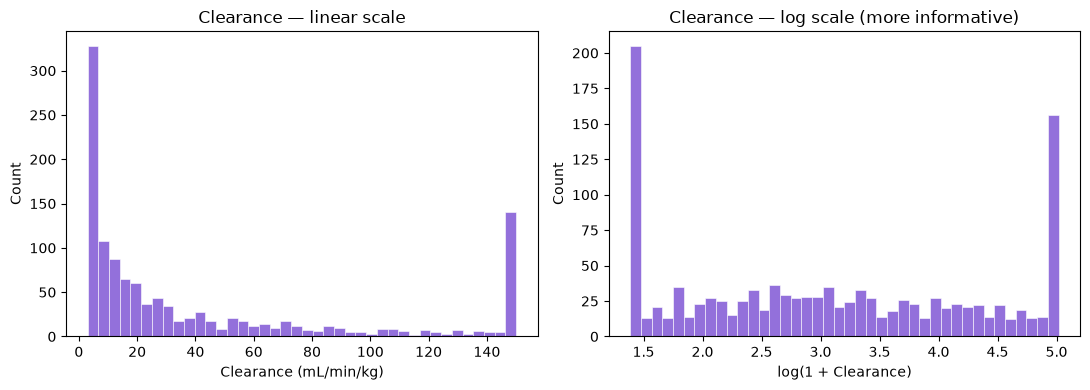

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df["Y"], bins=40, color="mediumpurple", edgecolor="white", linewidth=0.4)
axes[0].set_xlabel("Clearance (mL/min/kg)")
axes[0].set_ylabel("Count")
axes[0].set_title("Clearance — linear scale")

axes[1].hist(np.log1p(df["Y"]), bins=40, color="mediumpurple", edgecolor="white", linewidth=0.4)
axes[1].set_xlabel("log(1 + Clearance)")
axes[1].set_ylabel("Count")
axes[1].set_title("Clearance — log scale (more informative)")

plt.tight_layout()
plt.show()

---

## 5. hERG Toxicity

**What it is:** Binary label — does the molecule block the hERG cardiac potassium channel? `1` = blocker (toxic), `0` = non-blocker (safe).

**Why it matters:** hERG (KCNH2) controls cardiac repolarization — the electrical reset of the heart after each beat. Block it and you get QT interval prolongation, which can degenerate into torsades de pointes, a potentially fatal arrhythmia. Several approved drugs were withdrawn from the market for this reason (terfenadine, cisapride). This is one of the most important safety filters in drug discovery.

**Dataset:** ~655 compounds. Smallest dataset, but high clinical stakes.

⚠️ Class imbalance expected — hERG blockers are relatively rare in curated drug sets.


In [14]:
df = dfs[Endpoint.HERG]
df.head()

,Drug_ID,Drug,Y
0,DEMETHYLASTEMIZOLE,Oc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(F)cc3)CC2)cc1,1.0
1,GBR-12909,Fc1ccc(C(OCC[NH+]2CC[NH+](CCCc3ccccc3)CC2)c2cc...,1.0
2,LY-97241,CCCCCCCN(CC)CCCCc1ccc([N+](=O)[O-])cc1,1.0
3,CLOFILIUM PHOSPHATE,CCCCCCC[N+](CC)(CC)CCCCc1ccc(Cl)cc1.CCCCCCC[N+...,1.0
4,FLUSPIRILENE,O=C1NCN(c2ccccc2)C12CC[NH+](CCCC(c1ccc(F)cc1)c...,1.0


In [15]:
counts = df["Y"].value_counts().sort_index()
print(counts)
print(f"\nClass balance: {counts[1]/len(df)*100:.1f}% hERG blockers")

Y
0.0    204
1.0    451
Name: count, dtype: int64

Class balance: 68.9% hERG blockers


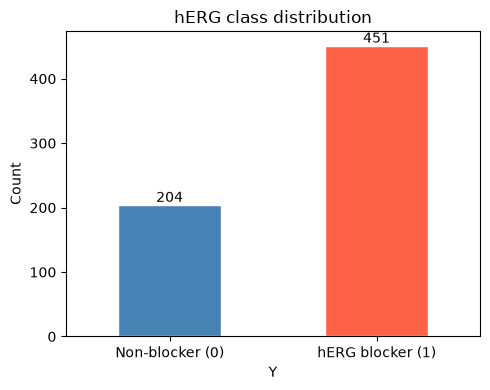

In [16]:
fig, ax = plt.subplots(figsize=(5, 4))
counts.plot(kind="bar", ax=ax, color=["steelblue", "tomato"], edgecolor="white", rot=0)
ax.set_xticklabels(["Non-blocker (0)", "hERG blocker (1)"])
ax.set_ylabel("Count")
ax.set_title("hERG class distribution")
for i, v in enumerate(counts):
    ax.text(i, v + 5, f"{v:,}", ha="center", fontsize=10)
plt.tight_layout()
plt.show()

---

## Summary

Key observations going into modeling:

- **Dataset sizes vary 15×** — CYP3A4 has 12k rows, hERG only 655. This will affect model confidence and generalization.
- **Clearance is right-skewed** — will likely need log transform before training.
- **CYP3A4 class balance** — check the bar chart above; significant imbalance means accuracy is a misleading metric, use AUC/AUPRC.
- **hERG is the smallest and highest-stakes** — class imbalance + small size = hardest to model reliably.
- **All 5 use scaffold split** — train/test sets have different molecular scaffolds (core ring systems), testing true generalization to new chemical series.
